<a href="https://colab.research.google.com/github/anupbagale/neural-networks-from-scratch/blob/main/notebooks/01_mcculloch_pitts_logic_gates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 1: McCulloch-Pitts Neurons and Logic Gates

Lesson 1 of 8, about 25 minutes.

After this lesson you should be able to:

1. Describe the McCulloch-Pitts neuron as a weighted sum followed by a threshold.
2. Choose weights and thresholds by hand for AND, OR, NOT, NAND and NOR.
3. Explain why a single threshold neuron cannot compute XOR.
4. Build XOR from a small two-layer network.

You will need: basic Python and NumPy, and truth tables from Boolean logic.

In [1]:
# Setup (works locally and on Google Colab)
try:
    import nnlab
except ImportError:  # not installed yet, e.g. on Colab
    %pip install -q "git+https://github.com/anupbagale/neural-networks-from-scratch"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## The model

McCulloch and Pitts (1943) described the first mathematical model of a neuron. It leaves out
almost all of the biology and keeps one idea: the neuron adds up its inputs and fires if the total
is large enough.

$$
net = \sum_{i=1}^{n} w_i x_i, \qquad
y = \begin{cases} 1 & \text{if } net \ge \theta \\ 0 & \text{otherwise} \end{cases}
$$

Here $x_i \in \{0, 1\}$ are the inputs, $w_i$ are fixed weights (positive weights excite, negative
weights inhibit) and $\theta$ is the threshold.

Nothing is learned yet. We pick the weights ourselves, so the only question is which weights and
threshold give the behaviour we want.

## A small example by hand

Take $w_1 = w_2 = 1$ and fill in the table before reading on.

| $x_1$ | $x_2$ | $net = x_1 + x_2$ | AND ($\theta = 2$) | OR ($\theta = 1$) |
|:-:|:-:|:-:|:-:|:-:|
| 0 | 0 | ? | ? | ? |
| 0 | 1 | ? | ? | ? |
| 1 | 0 | ? | ? | ? |
| 1 | 1 | ? | ? | ? |

The same weights give two different gates, and only the threshold changes. NOT, NAND and NOR are
made by inverting the output of a neuron.


**What are the outputs?**

<details><summary>Answer</summary>

$net$ is 0, 1, 1, 2. AND fires only when $net \ge 2$, giving 0 0 0 1. OR fires when $net \ge 1$, giving 0 1 1 1.

</details>

## The code

`nnlab.mcculloch_pitts` defines an `MPNeuron` with `weights`, a `threshold` and an optional
`inverted` flag. The gates from the original lab are collected in `GATES`.

In [2]:
from nnlab.mcculloch_pitts import GATES, MPNeuron, XOR_HIDDEN, truth_table, xor_network

for name, neuron in GATES.items():
    n_inputs = len(neuron.weights)
    print(f"{name}: w={neuron.weights}, threshold={neuron.threshold}, inverted={neuron.inverted}")
    for inputs, out in truth_table(neuron, n_inputs):
        print(f"    {inputs} -> {out}")

AND: w=(1, 1), threshold=2, inverted=False
    (0, 0) -> 0
    (0, 1) -> 0
    (1, 0) -> 0
    (1, 1) -> 1
OR: w=(1, 1), threshold=1, inverted=False
    (0, 0) -> 0
    (0, 1) -> 1
    (1, 0) -> 1
    (1, 1) -> 1
NOT: w=(1,), threshold=1, inverted=True
    (0,) -> 1
    (1,) -> 0
NAND: w=(1, 1), threshold=2, inverted=True
    (0, 0) -> 1
    (0, 1) -> 1
    (1, 0) -> 1
    (1, 1) -> 0
NOR: w=(1, 1), threshold=1, inverted=True
    (0, 0) -> 1
    (0, 1) -> 0
    (1, 0) -> 0
    (1, 1) -> 0


## Each neuron draws a line

The neuron fires when $w_1 x_1 + w_2 x_2 \ge \theta$. The boundary $w_1 x_1 + w_2 x_2 = \theta$
is a straight line in the input plane. Points on one side give 1 and points on the other side
give 0. Functions that one neuron can compute are called linearly separable.

In the plots below the shaded region is where the neuron outputs 1. Circles are inputs whose
correct output is 1 and crosses are inputs whose correct output is 0.

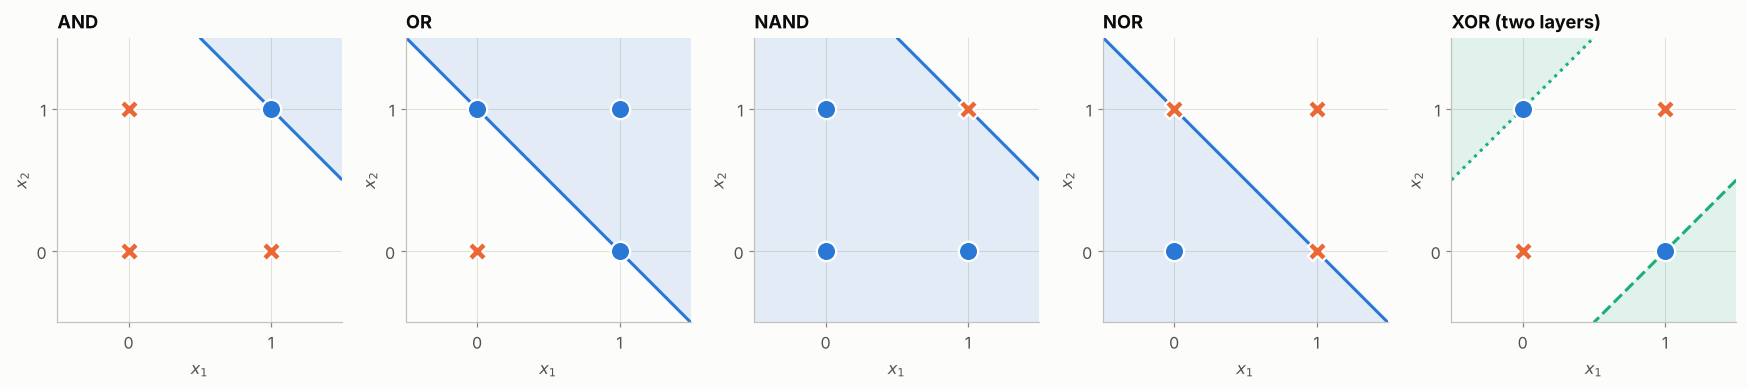

In [3]:
corners = np.array([(0, 0), (0, 1), (1, 0), (1, 1)])
grid = np.linspace(-0.5, 1.5, 300)
G1, G2 = np.meshgrid(grid, grid)


def draw_points(ax, outputs):
    for (x1, x2), out in zip(corners, outputs):
        ax.scatter(x1, x2, s=160, zorder=3,
                   marker="o" if out else "X",
                   color=PALETTE[0] if out else PALETTE[1],
                   edgecolor="white", linewidth=1.5)
    ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xticks=[0, 1], yticks=[0, 1],
           xlabel="$x_1$", ylabel="$x_2$", aspect="equal")


fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, name in zip(axes, ["AND", "OR", "NAND", "NOR"]):
    n = GATES[name]
    fires = (n.weights[0] * G1 + n.weights[1] * G2 >= n.threshold) != n.inverted
    ax.contourf(G1, G2, fires, levels=[0.5, 1.5], colors=[PALETTE[0]], alpha=0.12)
    ax.contour(G1, G2, n.weights[0] * G1 + n.weights[1] * G2, levels=[n.threshold],
               colors=[PALETTE[0]], linewidths=2)
    draw_points(ax, [out for _, out in truth_table(n)])
    ax.set_title(name)

ax = axes[4]
for w, ls in [((1, -1), "--"), ((-1, 1), ":")]:
    ax.contour(G1, G2, w[0] * G1 + w[1] * G2, levels=[1], colors=[PALETTE[2]], linewidths=2, linestyles=ls)
xor_region = (G1 - G2 >= 1) | (G2 - G1 >= 1)
ax.contourf(G1, G2, xor_region, levels=[0.5, 1.5], colors=[PALETTE[2]], alpha=0.12)
draw_points(ax, [out for _, out in truth_table(xor_network)])
ax.set_title("XOR (two layers)")

fig.tight_layout()
plt.show()

## Why XOR needs a second layer

In the XOR plot the two circles sit on opposite corners. No straight line puts both circles on one
side and both crosses on the other, so XOR is not linearly separable. Minsky and Papert (1969) made
this limitation of single-layer networks well known.

The way around it is to split the problem in two:

$$
\text{XOR}(x_1, x_2) = \underbrace{(x_1 \land \lnot x_2)}_{z_1:\ w=(1,-1),\ \theta=1}
\;\lor\; \underbrace{(\lnot x_1 \land x_2)}_{z_2:\ w=(-1,1),\ \theta=1}
$$

Each hidden neuron draws one of the two lines (dashed and dotted above), and the output neuron is
an OR gate that fires if either hidden neuron fires.

In [4]:
print("x1 x2 | z1 z2 | XOR")
for (x1, x2), out in truth_table(xor_network):
    z1, z2 = (neuron(x1, x2) for neuron in XOR_HIDDEN)
    print(f" {x1}  {x2} |  {z1}  {z2} |  {out}")

x1 x2 | z1 z2 | XOR
 0  0 |  0  0 |  0
 0  1 |  0  1 |  1
 1  0 |  1  0 |  1
 1  1 |  0  0 |  0


## Exercises

1. Design a single neuron for implication, $x_1 \Rightarrow x_2$, which is false only for
   $x_1 = 1, x_2 = 0$.
2. Build a 3-input majority gate that outputs 1 when at least two inputs are 1.
3. Build XNOR with a two-layer network.

In [5]:
# Exercise 1: replace the weights and threshold
implication = MPNeuron(weights=(0, 0), threshold=0)
print(truth_table(implication))   # should be [((0,0),1), ((0,1),1), ((1,0),0), ((1,1),1)]

# Exercise 2
majority = MPNeuron(weights=(0, 0, 0), threshold=0)
print([out for _, out in truth_table(majority, n_inputs=3)])  # should be [0,0,0,1,0,1,1,1]

[((0, 0), 1), ((0, 1), 1), ((1, 0), 1), ((1, 1), 1)]
[1, 1, 1, 1, 1, 1, 1, 1]


**Answers to the exercises**

<details><summary>Answer</summary>

1. $w = (-1, 1)$ and $\theta = 0$. The net input is negative only for $(1, 0)$.
2. $w = (1, 1, 1)$ and $\theta = 2$.
3. XNOR is NOT(XOR). Keep the two hidden neurons and use a NOR gate as the output neuron.

</details>

**Could one neuron compute XOR if we gave it more inputs?**

<details><summary>Answer</summary>

Not if the extra inputs are constants. A constant only shifts the line. One threshold neuron always splits its inputs with a single straight line (a hyperplane in more dimensions), and the XOR points cannot be split that way. You need a non-linear feature, such as the output of another neuron.

</details>

## Summary

- A McCulloch-Pitts neuron compares a weighted sum of its inputs with a threshold.
- Its decision boundary is a straight line, or a hyperplane in more dimensions.
- AND, OR, NAND, NOR and NOT are linearly separable. XOR is not.
- Putting neurons in layers makes non-linear decision regions possible.

Next: [Lesson 2, Activation Functions](02_activation_functions.ipynb)

### References

- McCulloch, W. S., & Pitts, W. (1943). A logical calculus of the ideas immanent in nervous activity. *Bulletin of Mathematical Biophysics*, 5(4), 115–133.
- Minsky, M., & Papert, S. (1969). *Perceptrons: An Introduction to Computational Geometry*. MIT Press.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.